In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [2]:
df = pd.read_csv("spam_ham_dataset.csv")

In [3]:
df.head(5)

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


In [4]:
df.tail(5)

,Unnamed: 0,label,text,label_num
5166,1518,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,404,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,2933,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,1409,ham,Subject: industrial worksheets for august 2000...,0
5170,4807,spam,Subject: important online banking alert\r\ndea...,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


In [6]:
df.shape

(5171, 4)

In [7]:
df.isnull().sum()

,0
Unnamed: 0,0
label,0
text,0
label_num,0


In [8]:
df.columns

Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')

In [9]:
df.dtypes

,0
Unnamed: 0,int64
label,object
text,object
label_num,int64


In [10]:
df.describe()

,Unnamed: 0,label_num
count,5171.000000,5171.000000
mean,2585.000000,0.289886
std,1492.883452,0.453753
min,0.000000,0.000000
25%,1292.500000,0.000000
50%,2585.000000,0.000000
75%,3877.500000,1.000000
max,5170.000000,1.000000


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["label"].value_counts()

,count
label,
ham,3672
spam,1499


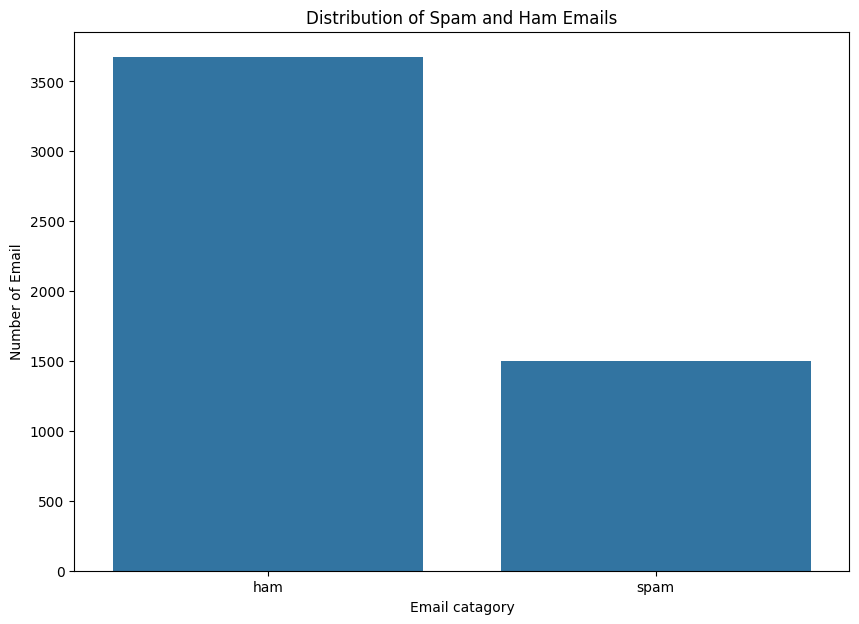

In [13]:
plt.figure(figsize=(10,7))
sns.countplot(x = "label",data = df)


plt.title("Distribution of Spam and Ham Emails")



plt.xlabel("Email catagory")



plt.ylabel("Number of Email")



plt.show()

In [14]:
df["text_length"]=df["text"].str.len()

In [15]:
df.head(10)

,Unnamed: 0,label,text,label_num,text_length
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0,327
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0,97
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0,2524
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1,414
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0,336
5,2949,ham,Subject: ehronline web address change\r\nthis ...,0,480
6,2793,ham,Subject: spring savings certificate - take 30 ...,0,2076
7,4185,spam,Subject: looking for medication ? we ` re the ...,1,784
8,2641,ham,Subject: noms / actual flow for 2 / 26\r\nwe a...,0,582
9,1870,ham,"Subject: nominations for oct . 21 - 23 , 2000\...",0,105


In [16]:
df["text_length"].describe()

,text_length
count,5171.000000
mean,1048.391994
std,1528.513435
min,11.000000
25%,244.000000
50%,540.000000
75%,1237.000000
max,32258.000000


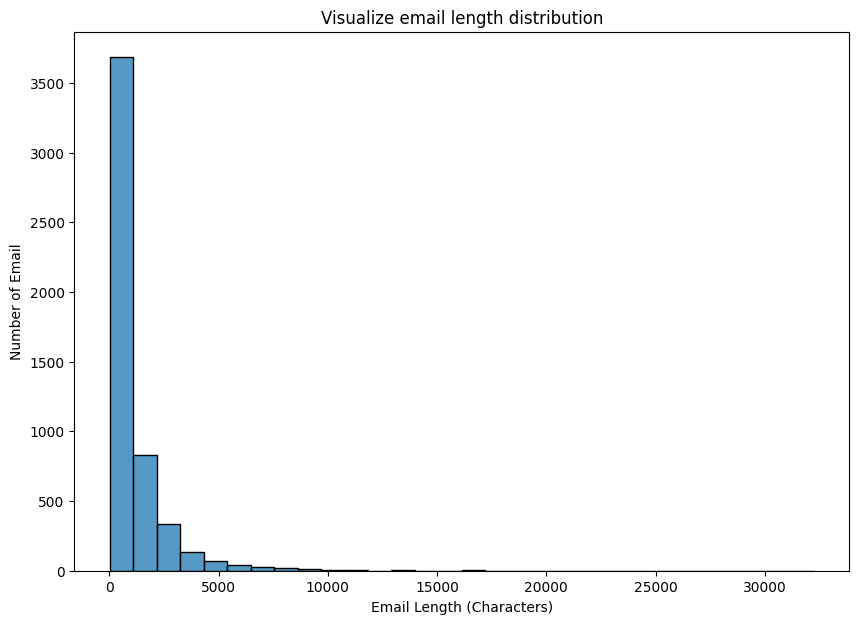

In [17]:
plt.figure(figsize=(10,7))
sns.histplot(x = "text_length",data = df, bins=30)


plt.title("Visualize email length distribution")



plt.xlabel("Email Length (Characters)")



plt.ylabel("Number of Email")



plt.show()

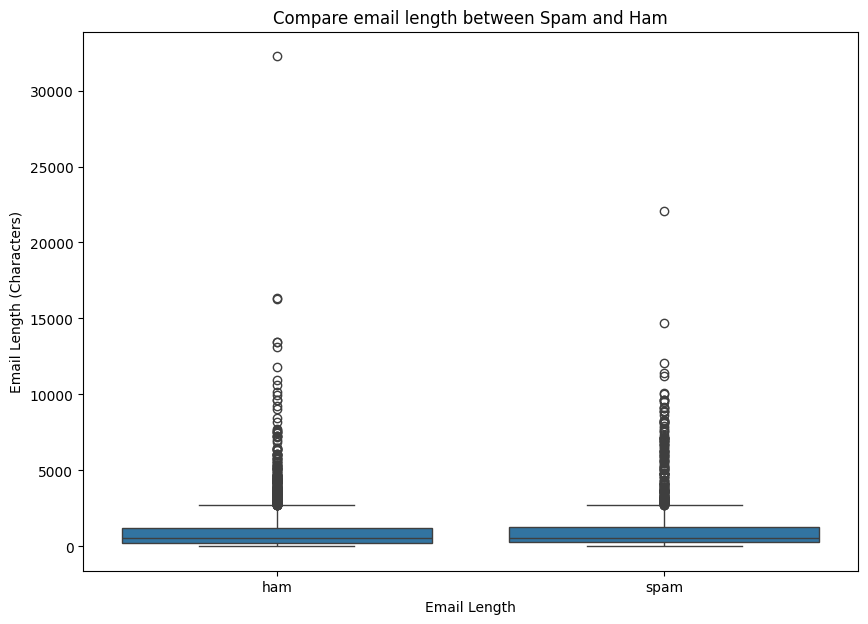

In [18]:
plt.figure(figsize=(10,7))
sns.boxplot(x = "label",y = "text_length",data = df)

plt.title("Compare email length between Spam and Ham")



plt.xlabel("Email Length")



plt.ylabel("Email Length (Characters)")



plt.show()

In [19]:
df.groupby("label")["text_length"].mean()

,text_length
label,
ham,977.008170
spam,1223.256171


In [20]:
df.drop(columns="Unnamed: 0",inplace=True)

In [21]:
df

,label,text,label_num,text_length
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0,327
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0,97
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0,2524
3,spam,"Subject: photoshop , windows , office . cheap ...",1,414
4,ham,Subject: re : indian springs\r\nthis deal is t...,0,336
...,...,...,...,...
5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0,534
5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0,1114
5168,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0,402
5169,ham,Subject: industrial worksheets for august 2000...,0,573


In [22]:
X = df["text"]
y = df["label_num"]

In [23]:
X.shape
y.shape

(5171,)

In [24]:
y.value_counts()

,count
label_num,
0,3672
1,1499


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [26]:
tfidf = TfidfVectorizer()

In [27]:
tfidf

TfidfVectorizer()

In [28]:
X_tfidf = tfidf.fit_transform(X)

In [29]:
X_tfidf.shape

(5171, 50447)

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [32]:
X_train.shape

(4136,)

In [33]:
X_test.shape

(1035,)

In [34]:
y_train.shape

(4136,)

In [35]:
y_test.shape

(1035,)

In [41]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

X_train_tfidf.shape
X_test_tfidf.shape

(1035, 43788)

In [42]:
from sklearn.naive_bayes import MultinomialNB

In [43]:
nb_model = MultinomialNB()

In [44]:
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [45]:
y_pred = nb_model.predict(X_test_tfidf)

In [46]:
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [47]:
print(y_test[:10])

774     0
2630    0
2543    0
3291    0
5024    0
1623    1
4935    0
3241    0
1504    0
5015    1
Name: label_num, dtype: int64


In [49]:
from sklearn.metrics import accuracy_score

In [50]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

Model Accuracy: 0.8879227053140096


In [52]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      1.00      0.93       735
           1       1.00      0.61      0.76       300

    accuracy                           0.89      1035
   macro avg       0.93      0.81      0.84      1035
weighted avg       0.90      0.89      0.88      1035



In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

cm

array([[735,   0],
       [116, 184]])

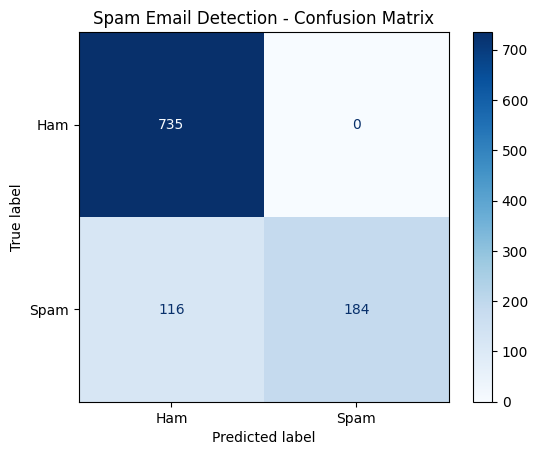

In [55]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Spam Email Detection - Confusion Matrix")
plt.show()

In [56]:
emails = [
    "Congratulations! You have won a free lottery. Claim your prize now!",
    "Hello, please find attached the meeting notes.",
    "You have won a cash prize. Click here to claim now!"
]

email_tfidf = tfidf.transform(emails)

predictions = nb_model.predict(email_tfidf)

for email, prediction in zip(emails, predictions):
    print(email)
    print("Spam" if prediction == 1 else "Ham")
    print()

Congratulations! You have won a free lottery. Claim your prize now!
Spam

Hello, please find attached the meeting notes.
Ham

You have won a cash prize. Click here to claim now!
Spam

